In [0]:


# TASK 3 - STEP 1: ML ENVIRONMENT AND DATASET VERIFICATION


from pyspark.sql import functions as F

# 1. Check Spark environment
print("=== DATABRICKS ML ENVIRONMENT ===")
print("Apache Spark Version:", spark.version)
print("Compute Environment: Databricks Serverless CPU")

# 2. Load existing cleaned Delta table
table_name = "workspace.default.dmart_sales_clean"

df = spark.table(table_name)

print("\n=== DATASET INFORMATION ===")
print("Source Table:", table_name)
print("Total Records:", df.count())
print("Total Columns:", len(df.columns))

# 3. Inspect dataset schema
print("\n=== DATASET SCHEMA ===")
df.printSchema()

# 4. Display sample records
print("\n=== SAMPLE TRANSACTION RECORDS ===")
display(df.limit(5))

# 5. Verify columns relevant to ML
print("\n=== ML COLUMN VERIFICATION ===")

ml_columns = [
    "Date",
    "ProductCategory",
    "Quantity",
    "Total",
    "CustomerType"
]

for column in ml_columns:
    if column in df.columns:
        print(column, ": AVAILABLE")
    else:
        print(column, ": MISSING")

# 6. Inspect correct chronological date range
print("\n=== DATE RANGE VERIFICATION ===")

display(
    df.select(
        F.min("TransactionDate").alias("EarliestDate"),
        F.max("TransactionDate").alias("LatestDate")
    )
)

# 7. Inspect customer type distribution
print("\n=== CUSTOMER TYPE DISTRIBUTION ===")

display(
    df.groupBy("CustomerType")
      .count()
      .orderBy(F.desc("count"))
)

# 8. Check Delta table metadata
print("\n=== DELTA TABLE INFORMATION ===")

display(
    spark.sql(f"DESCRIBE DETAIL {table_name}")
)

print("\nSTEP 1 EXECUTION COMPLETED")


=== DATABRICKS ML ENVIRONMENT ===
Apache Spark Version: 4.2.0
Compute Environment: Databricks Serverless CPU

=== DATASET INFORMATION ===
Source Table: workspace.default.dmart_sales_clean
Total Records: 1000000
Total Columns: 14

=== DATASET SCHEMA ===
root
 |-- Date: string (nullable = true)
 |-- Time: time(6) (nullable = true)
 |-- CustomerType: string (nullable = true)
 |-- ProductCategory: string (nullable = true)
 |-- UnitPrice: double (nullable = true)
 |-- Quantity: integer (nullable = true)
 |-- Total: double (nullable = true)
 |-- FullName: string (nullable = true)
 |-- TransactionTimestamp: timestamp (nullable = true)
 |-- TransactionDate: date (nullable = true)
 |-- Year: integer (nullable = true)
 |-- Month: integer (nullable = true)
 |-- DayOfWeek: integer (nullable = true)
 |-- Hour: integer (nullable = true)


=== SAMPLE TRANSACTION RECORDS ===


Date,Time,CustomerType,ProductCategory,UnitPrice,Quantity,Total,FullName,TransactionTimestamp,TransactionDate,Year,Month,DayOfWeek,Hour
31-12-2023 15:41,06:04:28,Member,Grocery,10.69,4,42.76,Jai Bhatia,2023-12-31T15:41:00.000Z,2023-12-31,2023,12,1,15
07-01-2024 22:19,01:05:18,Premium,Home & Kitchen,381.03,3,1143.09,Ishaan Patel,2024-01-07T22:19:00.000Z,2024-01-07,2024,1,1,22
10-01-2024 02:09,17:31:43,Regular,Grocery,153.84,5,769.2,Tanvi Iyer,2024-01-10T02:09:00.000Z,2024-01-10,2024,1,4,2
01-06-2023 10:46,01:50:16,Regular,Electronics,341.41,4,1365.64,Zara Xavier,2023-06-01T10:46:00.000Z,2023-06-01,2023,6,5,10
23-05-2024 22:07,10:37:06,Regular,Home & Kitchen,390.16,5,1950.8,Krishna Zutshi,2024-05-23T22:07:00.000Z,2024-05-23,2024,5,5,22



=== ML COLUMN VERIFICATION ===
Date : AVAILABLE
ProductCategory : AVAILABLE
Quantity : AVAILABLE
Total : AVAILABLE
CustomerType : AVAILABLE

=== DATE RANGE VERIFICATION ===


EarliestDate,LatestDate
2023-01-01,2025-01-09



=== CUSTOMER TYPE DISTRIBUTION ===


CustomerType,count
Premium,333480
Member,333408
Regular,333112



=== DELTA TABLE INFORMATION ===


format,id,name,description,location,createdAt,lastModified,partitionColumns,clusteringColumns,numFiles,sizeInBytes,properties,minReaderVersion,minWriterVersion,tableFeatures,statistics,clusterByAuto
delta,ad23ca8f-9045-4ca7-99ca-3f49cbf87d33,workspace.default.dmart_sales_clean,null,,2026-10-14T04:05:58.945Z,2026-10-26T04:46:39.000Z,List(),List(),1,27457997,"Map(delta.parquet.compression.codec -> zstd, delta.parquet.format.version.afe.internal -> 2.12.0, delta.enableDeletionVectors -> true, delta.parquet.format.version -> 2.12.0, io.unitycatalog.tableId -> 90dded40-0386-4542-8ea6-c5d8d166d7c7)",3,7,"List(appendOnly, deletionVectors, invariants, timeType-preview)","Map(numRowsDeletedByDeletionVectors -> 0, numDeletionVectors -> 0)",false



STEP 1 EXECUTION COMPLETED


In [0]:


# TASK 3 - STEP 2: DATE FORMAT AND TIME-SERIES PREPARATION


from pyspark.sql import functions as F

# 1. Load cleaned Delta Lake dataset
table_name = "workspace.default.dmart_sales_clean"
df = spark.table(table_name)

print("=== DATASET LOADED ===")
print("Source Table:", table_name)
print("Total Records:", df.count())

# 2. Convert original Date string to calendar date
# Original format: dd-MM-yyyy HH:mm

sales_df = df.withColumn(
    "SalesDate",
    F.to_date(
        F.try_to_timestamp(
            F.col("Date"),
            F.lit("dd-MM-yyyy HH:mm")
        )
    )
)

# 3. Validate date conversion
print("\n=== DATE CONVERSION VALIDATION ===")

display(
    sales_df.select(
        F.count("*").alias("TotalRecords"),
        F.sum(
            F.when(F.col("SalesDate").isNull(), 1).otherwise(0)
        ).alias("InvalidDates"),
        F.min("SalesDate").alias("EarliestDate"),
        F.max("SalesDate").alias("LatestDate")
    )
)

# 4. Compare converted dates with existing Delta dates
print("\n=== DATE CONSISTENCY VALIDATION ===")

display(
    sales_df.select(
        F.count("*").alias("TotalRecords"),
        F.sum(
            F.when(
                F.col("SalesDate").eqNullSafe(
                    F.col("TransactionDate")
                ),
                0
            ).otherwise(1)
        ).alias("DateMismatches"),
        F.min("SalesDate").alias("ParsedEarliest"),
        F.max("SalesDate").alias("ParsedLatest"),
        F.min("TransactionDate").alias("StoredEarliest"),
        F.max("TransactionDate").alias("StoredLatest")
    )
)

# 5. Aggregate transaction-level data into daily sales
print("\n=== DAILY SALES TRENDS ===")

daily_sales = (
    sales_df
    .filter(F.col("SalesDate").isNotNull())
    .groupBy("SalesDate")
    .agg(
        F.round(F.sum("Total"), 2).alias("DailySales"),
        F.count("*").alias("DailyTransactions")
    )
    .orderBy("SalesDate")
)

display(daily_sales.limit(20))

print("Number of Days:", daily_sales.count())

# 6. Verify continuous daily time-series coverage
print("\n=== DAILY TIME SERIES COMPLETENESS ===")

display(
    daily_sales.agg(
        F.count("*").alias("ObservedDays"),
        (
            F.datediff(
                F.max("SalesDate"),
                F.min("SalesDate")
            ) + 1
        ).alias("ExpectedCalendarDays")
    )
)

# 7. Calculate descriptive statistics
print("\n=== DAILY SALES SUMMARY STATISTICS ===")

display(
    daily_sales.select(
        F.min("SalesDate").alias("FirstDate"),
        F.max("SalesDate").alias("LastDate"),
        F.round(
            F.avg("DailySales"), 2
        ).alias("AverageDailySales"),
        F.round(
            F.stddev("DailySales"), 2
        ).alias("StdDevDailySales")
    )
)

print("\nSTEP 2 EXECUTION COMPLETED")


=== DATASET LOADED ===
Source Table: workspace.default.dmart_sales_clean
Total Records: 1000000

=== DATE CONVERSION VALIDATION ===


TotalRecords,InvalidDates,EarliestDate,LatestDate
1000000,0,2023-01-01,2025-01-09



=== DATE CONSISTENCY VALIDATION ===


TotalRecords,DateMismatches,ParsedEarliest,ParsedLatest,StoredEarliest,StoredLatest
1000000,0,2023-01-01,2025-01-09,2023-01-01,2025-01-09



=== DAILY SALES TRENDS ===


...

Number of Days: 740

=== DAILY TIME SERIES COMPLETENESS ===


ObservedDays,ExpectedCalendarDays
740,740



=== DAILY SALES SUMMARY STATISTICS ===


FirstDate,LastDate,AverageDailySales,StdDevDailySales
2023-01-01,2025-01-09,1033911.65,34642.72



STEP 2 EXECUTION COMPLETED


In [0]:

# STEP 3 - CELL 1
# Load and verify the cleaned dataset

from pyspark.sql import functions as F

table_name = "workspace.default.dmart_sales_clean"
df = spark.table(table_name)

print("=== DATASET VERIFICATION ===")
print("Total Records:", df.count())
print("Total Columns:", len(df.columns))

required_columns = [
    "Date",
    "ProductCategory",
    "Quantity",
    "Total",
    "CustomerType"
]

missing = [c for c in required_columns if c not in df.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

print("All required columns are available.")

df.printSchema()
display(df.select(*required_columns).limit(10))


=== DATASET VERIFICATION ===
Total Records: 1000000
Total Columns: 14
All required columns are available.
root
 |-- Date: string (nullable = true)
 |-- Time: time(6) (nullable = true)
 |-- CustomerType: string (nullable = true)
 |-- ProductCategory: string (nullable = true)
 |-- UnitPrice: double (nullable = true)
 |-- Quantity: integer (nullable = true)
 |-- Total: double (nullable = true)
 |-- FullName: string (nullable = true)
 |-- TransactionTimestamp: timestamp (nullable = true)
 |-- TransactionDate: date (nullable = true)
 |-- Year: integer (nullable = true)
 |-- Month: integer (nullable = true)
 |-- DayOfWeek: integer (nullable = true)
 |-- Hour: integer (nullable = true)



Date,ProductCategory,Quantity,Total,CustomerType
31-12-2023 15:41,Grocery,4,42.76,Member
07-01-2024 22:19,Home & Kitchen,3,1143.09,Premium
10-01-2024 02:09,Grocery,5,769.2,Regular
01-06-2023 10:46,Electronics,4,1365.64,Regular
23-05-2024 22:07,Home & Kitchen,5,1950.8,Regular
16-02-2024 19:41,Grocery,4,680.84,Member
30-11-2023 03:36,Clothing,2,163.48,Member
05-06-2024 05:21,Clothing,3,543.78,Premium
07-06-2024 21:40,Electronics,2,943.78,Premium
29-12-2023 04:35,Grocery,2,119.4,Member


Original dataset records: 1000000
Invalid dates: 0
Invalid quantities: 0
Invalid sales: 0
ML feature table saved successfully.
Daily sales table saved successfully.


CustomerType,count
Premium,333480
Member,333408
Regular,333112


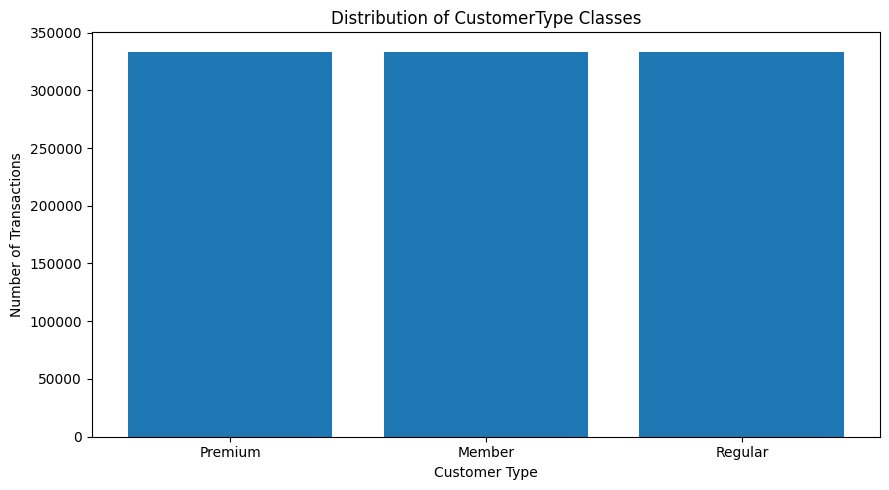

STEP 3 TABLES RESTORED AND STEP 4 CHART COMPLETED


In [0]:

# TASK 3C - FIX MISSING ML TABLE
# Restore Step 3 output and complete Step 4 chart

from pyspark.sql import functions as F
import matplotlib.pyplot as plt

# 1. Load original cleaned dataset
df = spark.table(
    "workspace.default.dmart_sales_clean"
)

print("Original dataset records:", df.count())

# 2. Recreate engineered features
ml_df = (
    df
    .withColumn(
        "SalesTimestamp",
        F.try_to_timestamp(
            F.col("Date"),
            F.lit("dd-MM-yyyy HH:mm")
        )
    )
    .withColumn("SalesDate", F.to_date("SalesTimestamp"))
    .withColumn("SalesYear", F.year("SalesDate"))
    .withColumn("SalesMonth", F.month("SalesDate"))
    .withColumn("SalesDayOfWeek", F.dayofweek("SalesDate"))
    .withColumn("SalesQuarter", F.quarter("SalesDate"))
    .withColumn(
        "IsWeekend",
        F.when(
            F.dayofweek("SalesDate").isin(1, 7), 1
        ).otherwise(0)
    )
    .withColumn("QuantityNumeric", F.col("Quantity").cast("double"))
    .withColumn("TotalNumeric", F.col("Total").cast("double"))
)

# 3. Validate before saving
checks = ml_df.agg(
    F.sum(F.col("SalesDate").isNull().cast("int")).alias("InvalidDates"),
    F.sum(F.col("QuantityNumeric").isNull().cast("int")).alias("InvalidQuantities"),
    F.sum(F.col("TotalNumeric").isNull().cast("int")).alias("InvalidSales")
).first()

print("Invalid dates:", checks["InvalidDates"])
print("Invalid quantities:", checks["InvalidQuantities"])
print("Invalid sales:", checks["InvalidSales"])

if any(checks[c] != 0 for c in checks.__fields__):
    raise ValueError("Invalid values found. Stop and inspect the data.")

# 4. Save the prepared transaction dataset
ml_df.write.format("delta").mode("overwrite").saveAsTable(
    "workspace.default.dmart_ml_features_3c"
)

print("ML feature table saved successfully.")

# 5. Recreate the daily sales table
daily_ml_df = (
    ml_df.groupBy("SalesDate")
    .agg(
        F.round(F.sum("TotalNumeric"), 2).alias("DailySales"),
        F.count("*").alias("TransactionCount"),
        F.sum("QuantityNumeric").alias("DailyQuantity")
    )
)

daily_ml_df.write.format("delta").mode("overwrite").saveAsTable(
    "workspace.default.dmart_daily_sales_3c"
)

print("Daily sales table saved successfully.")

# 6. Generate CustomerType distribution
class_distribution = (
    ml_df.groupBy("CustomerType")
    .count()
    .orderBy(F.desc("count"))
)

display(class_distribution)

class_pd = class_distribution.toPandas()

plt.figure(figsize=(9, 5))
plt.bar(
    class_pd["CustomerType"].fillna("Missing").astype(str),
    class_pd["count"]
)
plt.title("Distribution of CustomerType Classes")
plt.xlabel("Customer Type")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

print("STEP 3 TABLES RESTORED AND STEP 4 CHART COMPLETED")


In [0]:

# TASK 3C - STEP 5 - CELL 1
# Load prepared datasets

from pyspark.sql import functions as F

ml_df = spark.table(
    "workspace.default.dmart_ml_features_3c"
)

daily_ml_df = spark.table(
    "workspace.default.dmart_daily_sales_3c"
)

print("=== DATASET VERIFICATION ===")

print("Transaction records:", ml_df.count())
print("Daily sales records:", daily_ml_df.count())

display(
    ml_df.select(
        F.min("SalesDate").alias("FirstDate"),
        F.max("SalesDate").alias("LastDate"),
        F.countDistinct("SalesDate").alias("UniqueDates")
    )
)

print("STEP 5 - CELL 1 COMPLETED")


=== DATASET VERIFICATION ===
Transaction records: 1000000
Daily sales records: 740


FirstDate,LastDate,UniqueDates
2023-01-01,2025-01-09,740


STEP 5 - CELL 1 COMPLETED


In [0]:

# TASK 3C - STEP 5 - CELL 2
# Chronological split using distinct dates

from pyspark.sql.window import Window

dates_df = (
    ml_df
    .select("SalesDate")
    .where(F.col("SalesDate").isNotNull())
    .distinct()
)

date_window = Window.orderBy("SalesDate")

ranked_dates = dates_df.withColumn(
    "DateRank",
    F.row_number().over(date_window)
)

total_dates = ranked_dates.count()

if total_dates < 10:
    raise ValueError(
        "Insufficient distinct dates for an 80/20 split."
    )

train_date_count = int(total_dates * 0.80)

cutoff_date = (
    ranked_dates
    .filter(F.col("DateRank") == train_date_count)
    .select("SalesDate")
    .first()["SalesDate"]
)

print("=== CHRONOLOGICAL SPLIT ===")
print("Total observed dates:", total_dates)
print("Training cutoff date:", cutoff_date)

train_df = ml_df.filter(
    F.col("SalesDate") <= F.lit(cutoff_date)
)

test_df = ml_df.filter(
    F.col("SalesDate") > F.lit(cutoff_date)
)

print("Training records:", train_df.count())
print("Testing records:", test_df.count())

print("=== TRAINING DATE RANGE ===")
display(
    train_df.agg(
        F.min("SalesDate").alias("Start"),
        F.max("SalesDate").alias("End")
    )
)

print("=== TESTING DATE RANGE ===")
display(
    test_df.agg(
        F.min("SalesDate").alias("Start"),
        F.max("SalesDate").alias("End")
    )
)


/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


=== CHRONOLOGICAL SPLIT ===
Total observed dates: 740
Training cutoff date: 2024-08-14
Training records: 799908
Testing records: 200092
=== TRAINING DATE RANGE ===


Start,End
2023-01-01,2024-08-14


=== TESTING DATE RANGE ===


Start,End
2024-08-15,2025-01-09


In [0]:

# TASK 3C - STEP 5 - CELL 3
# Verify the split

train_max = train_df.agg(
    F.max("SalesDate")
).first()[0]

test_min = test_df.agg(
    F.min("SalesDate")
).first()[0]

print("=== LEAKAGE PREVENTION CHECK ===")

print("Latest training date:", train_max)
print("Earliest testing date:", test_min)

assert train_max < test_min, (
    "Date leakage detected between training and testing!"
)

assert train_df.count() + test_df.count() == ml_df.count(), (
    "Split record counts do not match the original dataset!"
)

print("PASS: No overlapping dates.")
print("PASS: All transaction records accounted for.")


=== LEAKAGE PREVENTION CHECK ===
Latest training date: 2024-08-14
Earliest testing date: 2024-08-15
PASS: No overlapping dates.
PASS: All transaction records accounted for.


In [0]:

# TASK 3C - STEP 5 - CELL 4
# Chronological split for daily sales forecasting

from pyspark.sql.window import Window

forecast_window = Window.orderBy("SalesDate")

ranked_daily = daily_ml_df.withColumn(
    "DateRank",
    F.row_number().over(forecast_window)
)

total_days = ranked_daily.count()

if total_days < 10:
    raise ValueError(
        "Insufficient daily observations for forecasting."
    )

forecast_train_days = int(total_days * 0.80)

forecast_cutoff = (
    ranked_daily
    .filter(F.col("DateRank") == forecast_train_days)
    .select("SalesDate")
    .first()["SalesDate"]
)

forecast_train = daily_ml_df.filter(
    F.col("SalesDate") <= F.lit(forecast_cutoff)
)

forecast_test = daily_ml_df.filter(
    F.col("SalesDate") > F.lit(forecast_cutoff)
)

print("=== FORECASTING TRAIN/TEST SPLIT ===")

print("Training days:", forecast_train.count())
print("Testing days:", forecast_test.count())
print("Forecasting cutoff date:", forecast_cutoff)

display(
    forecast_train.agg(
        F.min("SalesDate").alias("TrainStart"),
        F.max("SalesDate").alias("TrainEnd")
    )
)

display(
    forecast_test.agg(
        F.min("SalesDate").alias("TestStart"),
        F.max("SalesDate").alias("TestEnd")
    )
)


/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


=== FORECASTING TRAIN/TEST SPLIT ===
Training days: 592
Testing days: 148
Forecasting cutoff date: 2024-08-14


TrainStart,TrainEnd
2023-01-01,2024-08-14


TestStart,TestEnd
2024-08-15,2025-01-09


In [0]:

# TASK 3C - STEP 5 - CELL 5
# Class distribution after chronological split

print("=== TRAINING CLASS DISTRIBUTION ===")

display(
    train_df.groupBy("CustomerType")
    .count()
    .orderBy(F.desc("count"))
)

print("=== TESTING CLASS DISTRIBUTION ===")

display(
    test_df.groupBy("CustomerType")
    .count()
    .orderBy(F.desc("count"))
)

train_classes = {
    r["CustomerType"]
    for r in train_df.select("CustomerType").distinct().collect()
}

test_classes = {
    r["CustomerType"]
    for r in test_df.select("CustomerType").distinct().collect()
}

print("Classes absent from training:", test_classes - train_classes)
print("Classes absent from testing:", train_classes - test_classes)

if train_classes != test_classes:
    print(
        "WARNING: Class coverage differs. "
        "Review the split before classification."
    )
else:
    print("PASS: Same classes appear in both datasets.")


=== TRAINING CLASS DISTRIBUTION ===


CustomerType,count
Premium,266787
Regular,266631
Member,266490


=== TESTING CLASS DISTRIBUTION ===


CustomerType,count
Member,66918
Premium,66693
Regular,66481


Classes absent from training: set()
Classes absent from testing: set()
PASS: Same classes appear in both datasets.


In [0]:

# TASK 3C - STEP 5 - CELL 6
# Save the train/test datasets

tables = {
    "dmart_ml_train_3c": train_df,
    "dmart_ml_test_3c": test_df,
    "dmart_forecast_train_3c": forecast_train,
    "dmart_forecast_test_3c": forecast_test
}

for name, dataset in tables.items():
    full_name = f"workspace.default.{name}"

    dataset.write.format("delta") \
        .mode("overwrite") \
        .saveAsTable(full_name)

    print(
        "Saved:",
        full_name,
        "| Rows:",
        spark.table(full_name).count()
    )

print("STEP 5 COMPLETED")


Saved: workspace.default.dmart_ml_train_3c | Rows: 799908
Saved: workspace.default.dmart_ml_test_3c | Rows: 200092
Saved: workspace.default.dmart_forecast_train_3c | Rows: 592
Saved: workspace.default.dmart_forecast_test_3c | Rows: 148
STEP 5 COMPLETED


In [0]:

# TASK 3C - STEP 7: RANDOM FOREST CLASSIFICATION

from pyspark.sql import functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    StringIndexer, OneHotEncoder, VectorAssembler
)
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

# Load saved chronological training and testing datasets
train_df = spark.table("workspace.default.dmart_ml_train_3c")
test_df = spark.table("workspace.default.dmart_ml_test_3c")

target_col = "CustomerType"
feature_cols = [
    "ProductCategory",
    "SalesMonth",
    "SalesDayOfWeek",
    "SalesQuarter",
    "IsWeekend"
]

required_cols = [target_col, "SalesDate"] + feature_cols

# Validate required columns and missing values
for name, df in [("Training", train_df), ("Testing", test_df)]:
    missing_cols = [c for c in required_cols if c not in df.columns]

    if missing_cols:
        raise ValueError(f"{name} missing columns: {missing_cols}")

    null_condition = None
    for col_name in required_cols:
        condition = F.col(col_name).isNull()
        null_condition = (
            condition if null_condition is None
            else null_condition | condition
        )

    if df.filter(null_condition).limit(1).count() > 0:
        raise ValueError(f"{name} contains missing required values")

# Verify chronological separation
train_end = train_df.agg(F.max("SalesDate")).first()[0]
test_start = test_df.agg(F.min("SalesDate")).first()[0]

assert train_end < test_start, "Chronological leakage detected"

print("Training records:", train_df.count())
print("Testing records:", test_df.count())
print("Training end:", train_end)
print("Testing start:", test_start)

# Define preprocessing and classification pipeline
def build_rf_pipeline(trees=50, depth=8):
    return Pipeline(stages=[
        StringIndexer(
            inputCol="CustomerType",
            outputCol="label",
            handleInvalid="error",
            stringOrderType="alphabetAsc"
        ),
        StringIndexer(
            inputCol="ProductCategory",
            outputCol="CategoryIndex",
            handleInvalid="keep"
        ),
        OneHotEncoder(
            inputCols=["CategoryIndex"],
            outputCols=["CategoryVector"],
            handleInvalid="keep"
        ),
        VectorAssembler(
            inputCols=[
                "CategoryVector",
                "SalesMonth",
                "SalesDayOfWeek",
                "SalesQuarter",
                "IsWeekend"
            ],
            outputCol="features",
            handleInvalid="error"
        ),
        RandomForestClassifier(
            labelCol="label",
            featuresCol="features",
            numTrees=trees,
            maxDepth=depth,
            seed=42
        )
    ])

# Fit the complete pipeline on training data only
rf_pipeline_model = build_rf_pipeline(
    trees=50,
    depth=8
).fit(train_df)

# Predict on unseen testing data
rf_predictions = rf_pipeline_model.transform(test_df)

# Evaluate baseline Random Forest
evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction"
)

baseline_accuracy = evaluator.setMetricName(
    "accuracy"
).evaluate(rf_predictions)

baseline_f1 = evaluator.setMetricName(
    "f1"
).evaluate(rf_predictions)

print("\n=== STEP 7: BASELINE RANDOM FOREST ===")
print(f"Accuracy: {baseline_accuracy:.4f}")
print(f"Weighted F1: {baseline_f1:.4f}")

display(
    rf_predictions.select(
        "CustomerType",
        "label",
        "prediction",
        "probability"
    ).limit(10)
)

print("\nSTEP 7 COMPLETED")


Training records: 799908
Testing records: 200092
Training end: 2024-08-14
Testing start: 2024-08-15

=== STEP 7: BASELINE RANDOM FOREST ===
Accuracy: 0.3339
Weighted F1: 0.3337


CustomerType,label,prediction,probability
Regular,2.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.327284863162214"",""0.3418424374673451"",""0.3308726993704408""]}"
Member,0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.3289904092166013"",""0.3359532877912466"",""0.33505630299215217""]}"
Regular,2.0,2.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.3275402654828598"",""0.33428311863107674"",""0.3381766158860634""]}"
Regular,2.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.33666253919210815"",""0.3306238795147934"",""0.3327135812930985""]}"
Regular,2.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.3360074036176943"",""0.33642602382524633"",""0.3275665725570594""]}"
Regular,2.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.3394026514068511"",""0.3279994701283029"",""0.3325978784648459""]}"
Premium,1.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.33387302558732074"",""0.3336635033476473"",""0.332463471065032""]}"
Member,0.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.3336608060420611"",""0.3359841217616304"",""0.3303550721963085""]}"
Regular,2.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.337954512675943"",""0.33104656337449007"",""0.3309989239495668""]}"
Premium,1.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.33929197847131115"",""0.33464028465546836"",""0.32606773687322044""]}"



STEP 7 COMPLETED


=== CHRONOLOGICAL VALIDATION SPLIT ===
Training subset: 638451
Validation subset: 161457
Final test records: 200092
Validation cutoff: 2024-04-17

=== HYPERPARAMETER COMPARISON ===


Trees,MaxDepth,ValidationF1
20,5,0.3129
50,8,0.3277
80,10,0.3323



=== BEST CONFIGURATION ===
Trees: 80
Maximum depth: 10
Validation weighted F1: 0.3323

=== FINAL HELD-OUT TEST RESULTS ===
Test accuracy: 0.3331
Test weighted F1: 0.3331
Weighted precision: 0.3331
Weighted recall: 0.3331

=== CONFUSION MATRIX TABLE ===


Member,Premium,Regular
22278,22119,22521
22143,21858,22692
22198,21763,22520



=== CLASSIFICATION REPORT ===


Class,Precision,Recall,F1,Support
Member,0.3344,0.3329,0.3337,66918
Premium,0.3325,0.3277,0.3301,66693
Regular,0.3325,0.3387,0.3356,66481



=== ADDITIONAL METRICS ===
Macro F1: 0.3331
Balanced accuracy: 0.3331

=== MAJORITY-CLASS BASELINE ===
Training majority class: Premium
Accuracy: 0.3333
Weighted F1: 0.1666

=== FINAL MODEL COMPARISON ===


Model,Accuracy,WeightedF1
Majority-Class Baseline,0.3333,0.1666
"Random Forest Baseline (50, 8)",0.3339,0.3337
"Tuned Random Forest (80, 10)",0.3331,0.3331


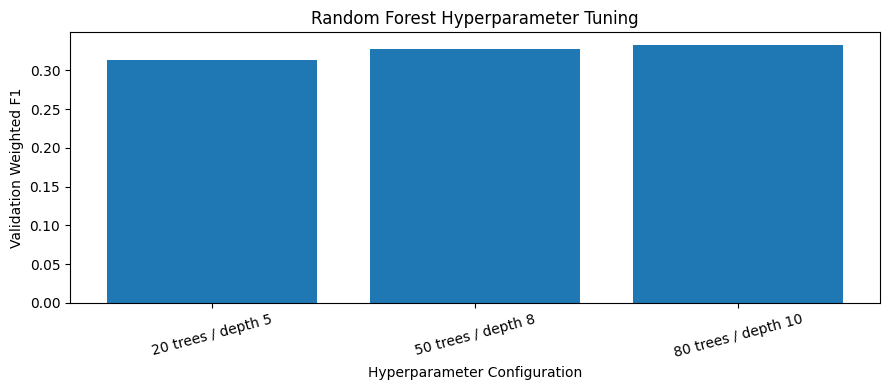

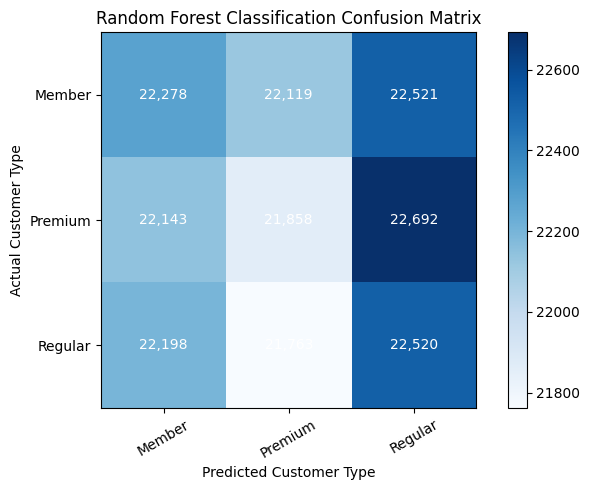

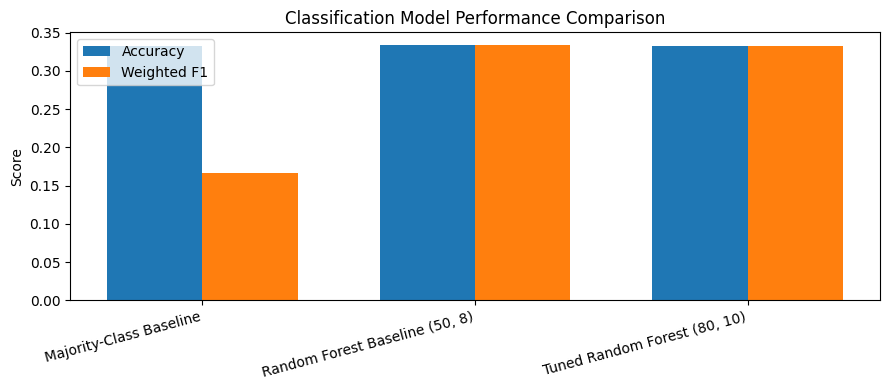


=== FINAL VERIFICATION ===
Tuning results saved
Classification report saved
Model comparison saved
Best Random Forest model available in current session

STEP 8 COMPLETED SUCCESSFULLY


In [0]:

# TASK 3C - STEP 8: RANDOM FOREST HYPERPARAMETER OPTIMISATION
# Chronological validation, evaluation and model comparison


from pyspark.sql import functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    StringIndexer, OneHotEncoder, VectorAssembler
)
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# 1. LOAD EXISTING TRAINING AND TESTING DATASETS

train_df = spark.table(
    "workspace.default.dmart_ml_train_3c"
)

test_df = spark.table(
    "workspace.default.dmart_ml_test_3c"
)

required_columns = [
    "SalesDate",
    "CustomerType",
    "ProductCategory",
    "SalesMonth",
    "SalesDayOfWeek",
    "SalesQuarter",
    "IsWeekend"
]

for name, df in [("Training", train_df), ("Testing", test_df)]:
    missing = [c for c in required_columns if c not in df.columns]
    if missing:
        raise ValueError(f"{name} missing columns: {missing}")

    invalid = df.filter(
        F.col("SalesDate").isNull() |
        F.col("CustomerType").isNull() |
        F.col("ProductCategory").isNull() |
        F.col("SalesMonth").isNull() |
        F.col("SalesDayOfWeek").isNull() |
        F.col("SalesQuarter").isNull() |
        F.col("IsWeekend").isNull()
    ).limit(1).count()

    if invalid:
        raise ValueError(f"{name} contains null required values")

train_end = train_df.agg(F.max("SalesDate")).first()[0]
test_start = test_df.agg(F.min("SalesDate")).first()[0]

assert train_end < test_start, (
    "Training and testing dates overlap"
)


# 2. CHRONOLOGICAL TRAINING / VALIDATION SPLIT


dates = sorted(
    row[0]
    for row in train_df.select("SalesDate").distinct().collect()
    if row[0] is not None
)

if len(dates) < 10:
    raise ValueError("Insufficient training dates")

cutoff_index = int(len(dates) * 0.8) - 1
validation_cutoff = dates[cutoff_index]

fit_df = train_df.filter(
    F.col("SalesDate") <= F.lit(validation_cutoff)
)

val_df = train_df.filter(
    F.col("SalesDate") > F.lit(validation_cutoff)
)

fit_count = fit_df.count()
val_count = val_df.count()
test_count = test_df.count()

assert fit_count + val_count == train_df.count()

print("=== CHRONOLOGICAL VALIDATION SPLIT ===")
print("Training subset:", fit_count)
print("Validation subset:", val_count)
print("Final test records:", test_count)
print("Validation cutoff:", validation_cutoff)

# ------------------------------------------------------------
# 3. DEFINE RANDOM FOREST PIPELINE
# ------------------------------------------------------------

def build_rf_pipeline(trees, depth):
    return Pipeline(stages=[
        StringIndexer(
            inputCol="CustomerType",
            outputCol="label",
            handleInvalid="error",
            stringOrderType="alphabetAsc"
        ),
        StringIndexer(
            inputCol="ProductCategory",
            outputCol="CategoryIndex",
            handleInvalid="keep"
        ),
        OneHotEncoder(
            inputCols=["CategoryIndex"],
            outputCols=["CategoryVector"],
            handleInvalid="keep"
        ),
        VectorAssembler(
            inputCols=[
                "CategoryVector",
                "SalesMonth",
                "SalesDayOfWeek",
                "SalesQuarter",
                "IsWeekend"
            ],
            outputCol="features",
            handleInvalid="error"
        ),
        RandomForestClassifier(
            labelCol="label",
            featuresCol="features",
            numTrees=trees,
            maxDepth=depth,
            seed=42
        )
    ])


# 4. HYPERPARAMETER COMPARISON


settings = [
    (20, 5),
    (50, 8),
    (80, 10)
]

validation_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="f1"
)

tuning_results = []

for trees, depth in settings:

    candidate_model = build_rf_pipeline(
        trees, depth
    ).fit(fit_df)

    validation_pred = candidate_model.transform(val_df)

    validation_f1 = validation_evaluator.evaluate(
        validation_pred
    )

    tuning_results.append({
        "Trees": trees,
        "MaxDepth": depth,
        "ValidationF1": float(validation_f1)
    })

tuning_df = pd.DataFrame(tuning_results)

print("\n=== HYPERPARAMETER COMPARISON ===")
display(tuning_df.round(4))


# 5. SELECT BEST HYPERPARAMETERS


best = max(
    tuning_results,
    key=lambda x: x["ValidationF1"]
)

best_trees = int(best["Trees"])
best_depth = int(best["MaxDepth"])
best_validation_f1 = float(best["ValidationF1"])

print("\n=== BEST CONFIGURATION ===")
print("Trees:", best_trees)
print("Maximum depth:", best_depth)
print("Validation weighted F1:", round(best_validation_f1, 4))


# 6. REFIT ON FULL TRAINING DATA


best_rf_model = build_rf_pipeline(
    best_trees,
    best_depth
).fit(train_df)

final_pred = best_rf_model.transform(test_df)

test_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction"
)

def evaluate_metric(predictions, metric):
    return test_evaluator.setMetricName(
        metric
    ).evaluate(predictions)

test_accuracy = evaluate_metric(final_pred, "accuracy")
test_f1 = evaluate_metric(final_pred, "f1")
test_weighted_precision = evaluate_metric(
    final_pred, "weightedPrecision"
)
test_weighted_recall = evaluate_metric(
    final_pred, "weightedRecall"
)

print("\n=== FINAL HELD-OUT TEST RESULTS ===")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test weighted F1: {test_f1:.4f}")
print(f"Weighted precision: {test_weighted_precision:.4f}")
print(f"Weighted recall: {test_weighted_recall:.4f}")


# 7. CONFUSION MATRIX


label_model = best_rf_model.stages[0]
class_names = list(label_model.labels)
n_classes = len(class_names)

confusion = np.zeros(
    (n_classes, n_classes),
    dtype=np.int64
)

confusion_rows = (
    final_pred
    .groupBy("label", "prediction")
    .count()
    .collect()
)

for row in confusion_rows:
    actual = int(row["label"])
    predicted = int(row["prediction"])

    confusion[actual, predicted] = int(row["count"])

confusion_df = pd.DataFrame(
    confusion,
    index=class_names,
    columns=class_names
)

print("\n=== CONFUSION MATRIX TABLE ===")
display(confusion_df)


# 8. PER-CLASS CLASSIFICATION REPORT

report_rows = []

for i, class_name in enumerate(class_names):

    tp = confusion[i, i]
    support = confusion[i, :].sum()
    predicted_count = confusion[:, i].sum()

    precision = (
        tp / predicted_count
        if predicted_count > 0 else 0.0
    )

    recall = (
        tp / support
        if support > 0 else 0.0
    )

    class_f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0.0
    )

    report_rows.append({
        "Class": class_name,
        "Precision": float(precision),
        "Recall": float(recall),
        "F1": float(class_f1),
        "Support": int(support)
    })

classification_report_df = pd.DataFrame(report_rows)

print("\n=== CLASSIFICATION REPORT ===")
display(classification_report_df.round(4))

macro_f1 = classification_report_df["F1"].mean()
balanced_accuracy = classification_report_df["Recall"].mean()

print("\n=== ADDITIONAL METRICS ===")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Balanced accuracy: {balanced_accuracy:.4f}")

# 9. MAJORITY-CLASS BASELINE


majority_row = (
    train_df
    .groupBy("CustomerType")
    .count()
    .orderBy(
        F.desc("count"),
        F.asc("CustomerType")
    )
    .first()
)

majority_class = majority_row["CustomerType"]

majority_correct = test_df.filter(
    F.col("CustomerType") == majority_class
).count()

majority_accuracy = majority_correct / test_count

# Compute majority-class weighted F1 from test support
test_support = (
    test_df.groupBy("CustomerType")
    .count()
    .collect()
)

support_map = {
    row["CustomerType"]: row["count"]
    for row in test_support
}

majority_support = support_map[majority_class]

majority_precision = majority_support / test_count
majority_recall = 1.0

majority_class_f1 = (
    2 * majority_precision * majority_recall /
    (majority_precision + majority_recall)
)

majority_weighted_f1 = (
    majority_support / test_count
) * majority_class_f1

print("\n=== MAJORITY-CLASS BASELINE ===")
print("Training majority class:", majority_class)
print(f"Accuracy: {majority_accuracy:.4f}")
print(f"Weighted F1: {majority_weighted_f1:.4f}")


# 10. BASELINE RANDOM FOREST VS TUNED RANDOM FOREST


# Evaluate the original Step 7 model when available.
# Otherwise, refit the same baseline configuration.
if "rf_pipeline_model" not in globals():
    print("\nRestoring Step 7 baseline model...")
    rf_pipeline_model = build_rf_pipeline(
        50, 8
    ).fit(train_df)

baseline_pred = rf_pipeline_model.transform(test_df)

baseline_accuracy = evaluate_metric(
    baseline_pred, "accuracy"
)

baseline_f1 = evaluate_metric(
    baseline_pred, "f1"
)

comparison_df = pd.DataFrame([
    {
        "Model": "Majority-Class Baseline",
        "Accuracy": majority_accuracy,
        "WeightedF1": majority_weighted_f1
    },
    {
        "Model": "Random Forest Baseline (50, 8)",
        "Accuracy": baseline_accuracy,
        "WeightedF1": baseline_f1
    },
    {
        "Model": f"Tuned Random Forest ({best_trees}, {best_depth})",
        "Accuracy": test_accuracy,
        "WeightedF1": test_f1
    }
])

print("\n=== FINAL MODEL COMPARISON ===")
display(comparison_df.round(4))


# 11. HYPERPARAMETER TUNING CHART


plt.figure(figsize=(9, 4))

config_labels = [
    f"{r['Trees']} trees / depth {r['MaxDepth']}"
    for r in tuning_results
]

plt.bar(
    config_labels,
    [r["ValidationF1"] for r in tuning_results]
)

plt.title("Random Forest Hyperparameter Tuning")
plt.ylabel("Validation Weighted F1")
plt.xlabel("Hyperparameter Configuration")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


# 12. CONFUSION MATRIX VISUALISATION


plt.figure(figsize=(7, 5))

plt.imshow(
    confusion,
    interpolation="nearest",
    cmap="Blues"
)

plt.colorbar()

plt.xticks(
    range(n_classes),
    class_names,
    rotation=30
)

plt.yticks(
    range(n_classes),
    class_names
)

plt.xlabel("Predicted Customer Type")
plt.ylabel("Actual Customer Type")
plt.title("Random Forest Classification Confusion Matrix")

threshold = confusion.max() / 2

for i in range(n_classes):
    for j in range(n_classes):

        plt.text(
            j, i,
            f"{confusion[i, j]:,}",
            ha="center",
            va="center",
            color=(
                "white"
                if confusion[i, j] > threshold
                else "black"
            )
        )

plt.tight_layout()
plt.show()


# 13. BASELINE VS TUNED MODEL CHART


plt.figure(figsize=(9, 4))

x = np.arange(len(comparison_df))
width = 0.35

plt.bar(
    x - width / 2,
    comparison_df["Accuracy"],
    width,
    label="Accuracy"
)

plt.bar(
    x + width / 2,
    comparison_df["WeightedF1"],
    width,
    label="Weighted F1"
)

plt.xticks(
    x,
    comparison_df["Model"],
    rotation=15,
    ha="right"
)

plt.ylabel("Score")
plt.title("Classification Model Performance Comparison")
plt.legend()
plt.tight_layout()
plt.show()


# 14. STORE RESULTS FOR LATER STEPS

# Models and metrics remain available in this notebook session.
# Persist the small evaluation tables as Delta tables.

spark.createDataFrame(
    tuning_df
).write.format("delta").mode("overwrite").saveAsTable(
    "workspace.default.dmart_rf_tuning_results_3c"
)

spark.createDataFrame(
    classification_report_df
).write.format("delta").mode("overwrite").saveAsTable(
    "workspace.default.dmart_rf_classification_report_3c"
)

spark.createDataFrame(
    comparison_df
).write.format("delta").mode("overwrite").saveAsTable(
    "workspace.default.dmart_rf_model_comparison_3c"
)

print("\n=== FINAL VERIFICATION ===")
print("Tuning results saved")
print("Classification report saved")
print("Model comparison saved")
print("Best Random Forest model available in current session")

print("\nSTEP 8 COMPLETED SUCCESSFULLY")


=== DAILY SALES DATA VALIDATION ===
Total daily records: 740
Unique dates: 740
Invalid records: 0
First date: 2023-01-01
Last date: 2025-01-09
Missing calendar days: 0


/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(



=== HISTORICAL FEATURE ENGINEERING ===
Original daily observations: 740
Records with valid lag features: 733
Initial observations removed: 7

=== CHRONOLOGICAL REGRESSION SPLIT ===
Training cutoff: 2024-08-14
Testing starts: 2024-08-15
Original training days: 592
Regression training records: 585
Regression testing records: 148

=== RANDOM FOREST REGRESSION TRAINING ===
Model: Random Forest Regressor
Trees: 50
Maximum depth: 8
Training records: 585
Testing records: 148

=== DAILY SALES PREDICTIONS ===


SalesDate,ActualSales,PredictedSales,PreviousDaySales
2024-08-15,1034966.96,1026664.3,1064002.98
2024-08-16,1080888.46,1035957.66,1034966.96
2024-08-17,1029771.19,1037046.66,1080888.46
2024-08-18,1008763.34,1028764.75,1029771.19
2024-08-19,1066928.99,1027992.73,1008763.34
2024-08-20,1056884.79,1022865.32,1066928.99
2024-08-21,1025675.38,1028034.78,1056884.79
2024-08-22,1006797.07,1027095.9,1025675.38
2024-08-23,1055778.55,1026475.17,1006797.07
2024-08-24,987773.48,1029736.74,1055778.55


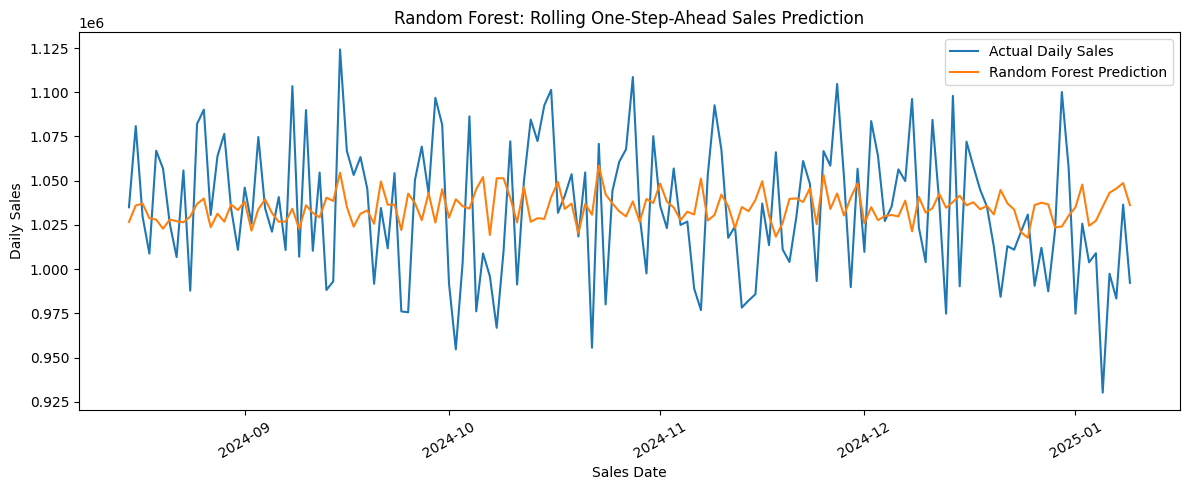


=== FINAL STEP 9 VERIFICATION ===
Daily sales data validated
Historical features generated
Chronological train/test split verified
Regression model trained successfully


/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


Prediction records: 148
Forecast method: Rolling one-step-ahead
Actual prior-day test sales used as lag inputs

STEP 9 COMPLETED SUCCESSFULLY


In [0]:

# TASK 3C - STEP 9: RANDOM FOREST SALES PREDICTION
# Rolling One-Step-Ahead Daily Sales Forecasting
# Databricks Serverless Compatible


from pyspark.sql import functions as F
from pyspark.sql.window import Window
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import RandomForestRegressor
import matplotlib.pyplot as plt


# 1. LOAD DAILY SALES DATASET


daily = (
    spark.table("workspace.default.dmart_daily_sales_3c")
    .select("SalesDate", "DailySales")
)


# 2. VALIDATE DAILY SALES DATA


total_rows = daily.count()

unique_dates = (
    daily.select("SalesDate")
    .distinct()
    .count()
)

invalid_rows = daily.filter(
    F.col("SalesDate").isNull() |
    F.col("DailySales").isNull() |
    F.isnan("DailySales")
).count()

if invalid_rows > 0:
    raise ValueError(
        f"Found {invalid_rows} invalid daily sales records."
    )

if total_rows != unique_dates:
    raise ValueError(
        "Duplicate SalesDate records detected."
    )

stats = daily.agg(
    F.min("SalesDate").alias("FirstDate"),
    F.max("SalesDate").alias("LastDate")
).first()

first_date = stats["FirstDate"]
last_date = stats["LastDate"]

calendar_days = (last_date - first_date).days + 1

if unique_dates != calendar_days:
    raise ValueError(
        "Missing calendar dates detected. "
        "Historical lag features require consecutive dates."
    )

print("=== DAILY SALES DATA VALIDATION ===")
print("Total daily records:", total_rows)
print("Unique dates:", unique_dates)
print("Invalid records:", invalid_rows)
print("First date:", first_date)
print("Last date:", last_date)
print("Missing calendar days:", calendar_days - unique_dates)


# 3. CREATE HISTORICAL SALES FEATURES


# Lag features use only previous observations.
# Current-day DailySales is excluded from predictor inputs.

w = Window.orderBy("SalesDate")

sales_features = (
    daily
    .withColumn(
        "Lag1",
        F.lag("DailySales", 1).over(w)
    )
    .withColumn(
        "Lag7",
        F.lag("DailySales", 7).over(w)
    )
    .withColumn(
        "Rolling7",
        F.avg("DailySales").over(
            w.rowsBetween(-7, -1)
        )
    )
    .withColumn(
        "Month",
        F.month("SalesDate")
    )
    .withColumn(
        "DayOfWeek",
        F.dayofweek("SalesDate")
    )
    .dropna(
        subset=[
            "Lag1",
            "Lag7",
            "Rolling7",
            "Month",
            "DayOfWeek"
        ]
    )
)

feature_count = sales_features.count()

print("\n=== HISTORICAL FEATURE ENGINEERING ===")
print("Original daily observations:", total_rows)
print("Records with valid lag features:", feature_count)
print("Initial observations removed:", total_rows - feature_count)


# 4. RESTORE CHRONOLOGICAL FORECASTING SPLIT


forecast_train = spark.table(
    "workspace.default.dmart_forecast_train_3c"
)

forecast_test = spark.table(
    "workspace.default.dmart_forecast_test_3c"
)

cutoff = forecast_train.agg(
    F.max("SalesDate")
).first()[0]

test_start = forecast_test.agg(
    F.min("SalesDate")
).first()[0]

if cutoff >= test_start:
    raise ValueError(
        "Chronological train/test overlap detected."
    )

train_reg = sales_features.filter(
    F.col("SalesDate") <= F.lit(cutoff)
)

test_reg = sales_features.filter(
    F.col("SalesDate") > F.lit(cutoff)
)

train_count = train_reg.count()
test_count = test_reg.count()

expected_train = forecast_train.count()
expected_test = forecast_test.count()

# First 7 training days are removed because Lag7 is unavailable.
if train_count != expected_train - 7:
    raise ValueError(
        "Unexpected training record count after lag creation."
    )

if test_count != expected_test:
    raise ValueError(
        "Unexpected test record count."
    )

print("\n=== CHRONOLOGICAL REGRESSION SPLIT ===")
print("Training cutoff:", cutoff)
print("Testing starts:", test_start)
print("Original training days:", expected_train)
print("Regression training records:", train_count)
print("Regression testing records:", test_count)


# 5. DEFINE REGRESSION FEATURES AND PIPELINE


feature_columns = [
    "Lag1",
    "Lag7",
    "Rolling7",
    "Month",
    "DayOfWeek"
]

regression_pipeline = Pipeline(stages=[
    VectorAssembler(
        inputCols=feature_columns,
        outputCol="features",
        handleInvalid="error"
    ),
    RandomForestRegressor(
        featuresCol="features",
        labelCol="DailySales",
        predictionCol="prediction",
        numTrees=50,
        maxDepth=8,
        seed=42
    )
])


# 6. TRAIN RANDOM FOREST REGRESSION MODEL


print("\n=== RANDOM FOREST REGRESSION TRAINING ===")

regression_model = regression_pipeline.fit(train_reg)

regression_predictions = regression_model.transform(test_reg)

print("Model: Random Forest Regressor")
print("Trees: 50")
print("Maximum depth: 8")
print("Training records:", train_count)
print("Testing records:", test_count)


# 7. DISPLAY DAILY SALES PREDICTIONS


print("\n=== DAILY SALES PREDICTIONS ===")

display(
    regression_predictions
    .select(
        "SalesDate",
        F.round("DailySales", 2).alias("ActualSales"),
        F.round("prediction", 2).alias("PredictedSales"),
        F.round("Lag1", 2).alias("PreviousDaySales")
    )
    .orderBy("SalesDate")
    .limit(15)
)


# 8. VISUALISE ACTUAL VS PREDICTED DAILY SALES

# Only 148 test observations are converted to Pandas.

plot_pd = (
    regression_predictions
    .select(
        "SalesDate",
        "DailySales",
        "prediction"
    )
    .orderBy("SalesDate")
    .toPandas()
)

plt.figure(figsize=(12, 5))

plt.plot(
    plot_pd["SalesDate"],
    plot_pd["DailySales"],
    label="Actual Daily Sales",
    linewidth=1.5
)

plt.plot(
    plot_pd["SalesDate"],
    plot_pd["prediction"],
    label="Random Forest Prediction",
    linewidth=1.5
)

plt.title(
    "Random Forest: Rolling One-Step-Ahead Sales Prediction"
)
plt.xlabel("Sales Date")
plt.ylabel("Daily Sales")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# 9. FINAL VALIDATION


print("\n=== FINAL STEP 9 VERIFICATION ===")
print("Daily sales data validated")
print("Historical features generated")
print("Chronological train/test split verified")
print("Regression model trained successfully")
print("Prediction records:", regression_predictions.count())
print("Forecast method: Rolling one-step-ahead")
print("Actual prior-day test sales used as lag inputs")

print("\nSTEP 9 COMPLETED SUCCESSFULLY")


/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


=== STEP 10: REGRESSION EVALUATION ===


Model,MAE,RMSE,R2
Random Forest,32026.136,39020.2878,-0.0535
Previous-day baseline,42147.9786,51088.7274,-0.8059



=== MODEL COMPARISON ===
Random Forest outperformed the baseline on MAE.


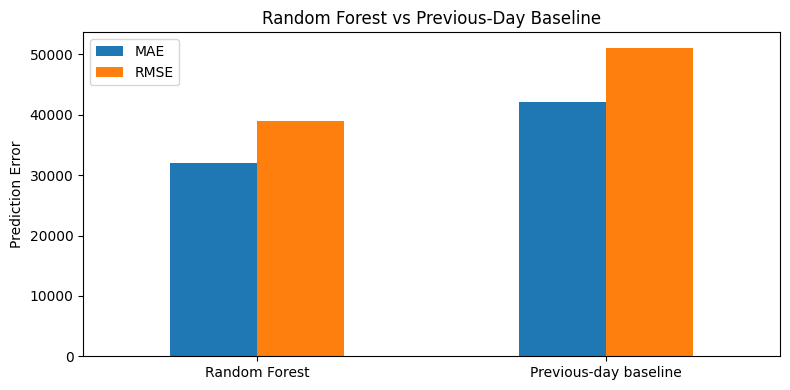


STEP 10 COMPLETED SUCCESSFULLY


In [0]:

# TASK 3C - STEP 10 ONLY
# SERVERLESS-COMPATIBLE REGRESSION EVALUATION

from pyspark.ml.evaluation import RegressionEvaluator
import pandas as pd
import matplotlib.pyplot as plt

# Uses regression_predictions created in Step 9
# No PERSIST TABLE or cache operations

evaluator = RegressionEvaluator(labelCol="DailySales")

results = []

for model_name, prediction_column in [
    ("Random Forest", "prediction"),
    ("Previous-day baseline", "Lag1")
]:
    row = {"Model": model_name}

    for metric, label in [
        ("mae", "MAE"),
        ("rmse", "RMSE"),
        ("r2", "R2")
    ]:
        evaluator.setPredictionCol(prediction_column)
        evaluator.setMetricName(metric)

        row[label] = evaluator.evaluate(
            regression_predictions
        )

    results.append(row)

results_df = pd.DataFrame(results)

print("=== STEP 10: REGRESSION EVALUATION ===")
display(results_df.round(4))

rf_mae = results_df.loc[
    results_df["Model"] == "Random Forest", "MAE"
].iloc[0]

baseline_mae = results_df.loc[
    results_df["Model"] == "Previous-day baseline", "MAE"
].iloc[0]

print("\n=== MODEL COMPARISON ===")

if rf_mae < baseline_mae:
    print("Random Forest outperformed the baseline on MAE.")
elif rf_mae > baseline_mae:
    print("Previous-day baseline outperformed Random Forest on MAE.")
else:
    print("Both models achieved the same MAE.")

# Comparison chart
results_df.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(8, 4)
)

plt.title("Random Forest vs Previous-Day Baseline")
plt.ylabel("Prediction Error")
plt.xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("\nSTEP 10 COMPLETED SUCCESSFULLY")


=== TIME-SERIES DATA QUALITY ===
Observed Days: 740
First Date: 2023-01-01
Last Date: 2025-01-09
Missing Calendar Days: 0

=== TIME-SERIES SPLIT ===
Training Days: 592
Testing Days: 148
Training End: 2024-08-14
Testing Start: 2024-08-15

=== SALES SUMMARY ===
count        740.00
mean     1033911.65
std        34642.72
min       929910.43
25%      1009345.24
50%      1034424.60
75%      1056753.07
max      1142995.66
Name: DailySales, dtype: float64


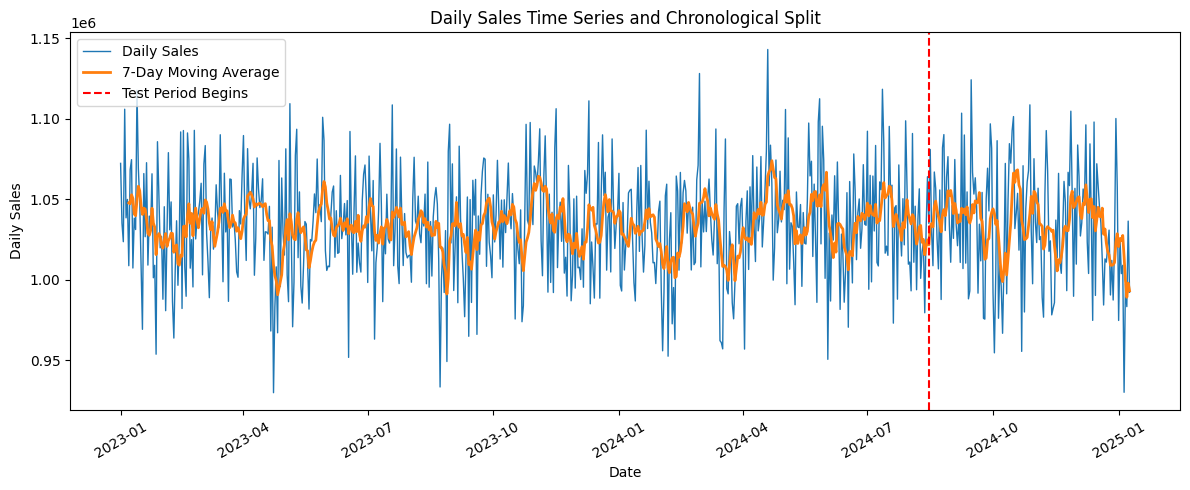


STEP 11 COMPLETED SUCCESSFULLY


In [0]:

# TASK 3C - STEP 11
# TIME-SERIES PREPARATION AND VISUALISATION

from pyspark.sql import functions as F
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load daily sales from Delta Lake
daily_df = spark.table(
    "workspace.default.dmart_daily_sales_3c"
).select("SalesDate", "DailySales")

# 2. Convert daily aggregates to Pandas
# Only aggregated daily data, not 1 million transactions
sales_pd = daily_df.orderBy("SalesDate").toPandas()

sales_pd["SalesDate"] = pd.to_datetime(
    sales_pd["SalesDate"]
)

sales_pd["DailySales"] = pd.to_numeric(
    sales_pd["DailySales"],
    errors="coerce"
)

# 3. Validate the series
if sales_pd.empty:
    raise ValueError("Daily sales dataset is empty.")

if sales_pd["SalesDate"].isna().any():
    raise ValueError("Invalid sales dates detected.")

if sales_pd["SalesDate"].duplicated().any():
    raise ValueError("Duplicate sales dates detected.")

if sales_pd["DailySales"].isna().any():
    raise ValueError("Missing or invalid sales amounts detected.")

# 4. Create daily date index
sales_pd = sales_pd.set_index("SalesDate").sort_index()

full_dates = pd.date_range(
    sales_pd.index.min(),
    sales_pd.index.max(),
    freq="D"
)

missing_dates = full_dates.difference(sales_pd.index)

print("=== TIME-SERIES DATA QUALITY ===")
print("Observed Days:", len(sales_pd))
print("First Date:", sales_pd.index.min().date())
print("Last Date:", sales_pd.index.max().date())
print("Missing Calendar Days:", len(missing_dates))

if len(missing_dates) > 0:
    print("First missing dates:", list(missing_dates[:10]))
    raise ValueError(
        "Missing calendar dates require investigation "
        "before ARIMA/SARIMA modelling."
    )

# 5. Define regularly spaced sales series
sales_series = sales_pd["DailySales"].asfreq("D")

# 6. Chronological 80/20 split
split_idx = int(len(sales_series) * 0.80)

if split_idx < 14 or len(sales_series) - split_idx < 7:
    raise ValueError(
        "Insufficient observations for the planned forecast evaluation."
    )

ts_train = sales_series.iloc[:split_idx]
ts_test = sales_series.iloc[split_idx:]

print("\n=== TIME-SERIES SPLIT ===")
print("Training Days:", len(ts_train))
print("Testing Days:", len(ts_test))
print("Training End:", ts_train.index.max().date())
print("Testing Start:", ts_test.index.min().date())

print("\n=== SALES SUMMARY ===")
print(sales_series.describe().round(2))

# 7. Historical sales chart
plt.figure(figsize=(12, 5))
plt.plot(sales_series.index, sales_series.values,
         label="Daily Sales", linewidth=1)
plt.plot(
    sales_series.rolling(7).mean(),
    label="7-Day Moving Average",
    linewidth=2
)
plt.axvline(
    ts_test.index.min(),
    color="red",
    linestyle="--",
    label="Test Period Begins"
)

plt.title("Daily Sales Time Series and Chronological Split")
plt.xlabel("Date")
plt.ylabel("Daily Sales")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print("\nSTEP 11 COMPLETED SUCCESSFULLY")


In [0]:

%pip install statsmodels


Looking in indexes: [REDACTED]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 99.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [statsmodels]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


=== TIME-SERIES VALIDATION ===
Observed Days: 740
Missing Calendar Days: 0

=== DATASET SPLIT ===
Training Days: 592
Testing Days: 148
Training End: 2024-08-14
Testing Start: 2024-08-15

=== ARIMA CONFIGURATION ===
Model: ARIMA(1,1,1)
ARIMA model trained successfully.

=== ARIMA EVALUATION RESULTS ===
MAE: 31713.8141
RMSE: 38069.0766
MAPE: 3.08%

=== SAMPLE FORECAST RESULTS ===


Date,ActualSales,ForecastSales
2024-08-15T00:00:00.000Z,1034966.96,1042266.89
2024-08-16T00:00:00.000Z,1080888.46,1037328.84
2024-08-17T00:00:00.000Z,1029771.19,1036207.0
2024-08-18T00:00:00.000Z,1008763.34,1035952.14
2024-08-19T00:00:00.000Z,1066928.99,1035894.24
2024-08-20T00:00:00.000Z,1056884.79,1035881.08
2024-08-21T00:00:00.000Z,1025675.38,1035878.09
2024-08-22T00:00:00.000Z,1006797.07,1035877.42
2024-08-23T00:00:00.000Z,1055778.55,1035877.26
2024-08-24T00:00:00.000Z,987773.48,1035877.23


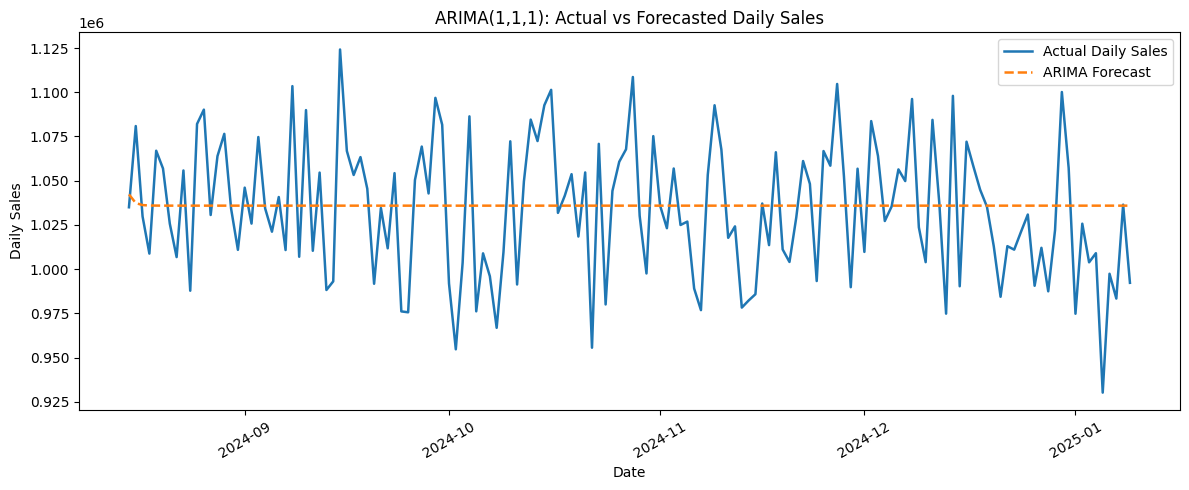


STEP 12 COMPLETED SUCCESSFULLY


In [0]:


# TASK 3C - STEP 12: ARIMA SALES FORECASTING
# DATABRICKS SERVERLESS COMPATIBLE

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. LOAD DAILY SALES DATA
# Reload from Delta so this cell is self-contained

daily_df = spark.table(
    "workspace.default.dmart_daily_sales_3c"
).select("SalesDate", "DailySales")

sales_pd = daily_df.orderBy("SalesDate").toPandas()

sales_pd["SalesDate"] = pd.to_datetime(
    sales_pd["SalesDate"], errors="coerce"
)

sales_pd["DailySales"] = pd.to_numeric(
    sales_pd["DailySales"], errors="coerce"
)

# 2. VALIDATE TIME SERIES

if sales_pd.empty:
    raise ValueError("Daily sales dataset is empty.")

if sales_pd["SalesDate"].isna().any():
    raise ValueError("Invalid dates detected.")

if sales_pd["SalesDate"].duplicated().any():
    raise ValueError("Duplicate dates detected.")

if sales_pd["DailySales"].isna().any():
    raise ValueError("Invalid sales values detected.")

sales_series = (
    sales_pd
    .set_index("SalesDate")["DailySales"]
    .sort_index()
)

# Verify no missing calendar dates
full_dates = pd.date_range(
    sales_series.index.min(),
    sales_series.index.max(),
    freq="D"
)

missing_dates = full_dates.difference(sales_series.index)

print("=== TIME-SERIES VALIDATION ===")
print("Observed Days:", len(sales_series))
print("Missing Calendar Days:", len(missing_dates))

if len(missing_dates) > 0:
    print("Example missing dates:", list(missing_dates[:10]))
    raise ValueError(
        "Missing calendar dates detected. "
        "Investigate before fitting ARIMA."
    )

sales_series = sales_series.asfreq("D")

# 3. CHRONOLOGICAL TRAIN/TEST SPLIT

split_index = int(len(sales_series) * 0.80)

ts_train = sales_series.iloc[:split_index]
ts_test = sales_series.iloc[split_index:]

if len(ts_train) < 14 or len(ts_test) < 7:
    raise ValueError("Insufficient data for ARIMA evaluation.")

print("\n=== DATASET SPLIT ===")
print("Training Days:", len(ts_train))
print("Testing Days:", len(ts_test))
print("Training End:", ts_train.index.max().date())
print("Testing Start:", ts_test.index.min().date())

# 4. TRAIN ARIMA MODEL

print("\n=== ARIMA CONFIGURATION ===")
print("Model: ARIMA(1,1,1)")

arima_model = ARIMA(
    ts_train,
    order=(1, 1, 1)
)

arima_result = arima_model.fit()

print("ARIMA model trained successfully.")

# 5. FORECAST HELD-OUT TEST PERIOD

arima_forecast = arima_result.forecast(
    steps=len(ts_test)
)

arima_forecast = pd.Series(
    np.asarray(arima_forecast),
    index=ts_test.index,
    name="ForecastSales"
)

# 6. CALCULATE EVALUATION METRICS

actual = ts_test.to_numpy()
predicted = arima_forecast.to_numpy()

mae = mean_absolute_error(actual, predicted)

rmse = np.sqrt(
    mean_squared_error(actual, predicted)
)

# MAPE excludes zero actual sales
nonzero = actual != 0

if nonzero.any():
    mape = np.mean(
        np.abs(
            (actual[nonzero] - predicted[nonzero])
            / actual[nonzero]
        )
    ) * 100
else:
    mape = np.nan

print("\n=== ARIMA EVALUATION RESULTS ===")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")

if np.isfinite(mape):
    print(f"MAPE: {mape:.2f}%")
else:
    print("MAPE: Undefined (no nonzero actual sales)")

# 7. DISPLAY FORECAST TABLE

forecast_results = pd.DataFrame({
    "Date": ts_test.index,
    "ActualSales": actual,
    "ForecastSales": predicted
})

print("\n=== SAMPLE FORECAST RESULTS ===")
display(forecast_results.head(15).round(2))

# 8. ACTUAL VS FORECAST CHART

plt.figure(figsize=(12, 5))

plt.plot(
    ts_test.index,
    actual,
    label="Actual Daily Sales",
    linewidth=1.8
)

plt.plot(
    arima_forecast.index,
    predicted,
    label="ARIMA Forecast",
    linestyle="--",
    linewidth=1.8
)

plt.title("ARIMA(1,1,1): Actual vs Forecasted Daily Sales")
plt.xlabel("Date")
plt.ylabel("Daily Sales")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print("\nSTEP 12 COMPLETED SUCCESSFULLY")


In [0]:
%pip install statsmodels

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


SARIMA converged: True

=== STEP 13: FORECAST COMPARISON ===


Model,MAE,RMSE,MAPE (%)
"ARIMA(1,1,1)",31713.8141,38069.0766,3.0811
"SARIMA(1,1,1)(1,0,1,7)",31638.0893,38046.0745,3.0674
Seasonal-Naive (7-day),41405.012,51029.4298,3.9909



=== SAMPLE FORECASTS ===


Date,Actual,ARIMA,SARIMA,SeasonalNaive
2024-08-15T00:00:00.000Z,1034966.96,1042266.89,1035134.66,1056482.47
2024-08-16T00:00:00.000Z,1080888.46,1037328.84,1032166.18,1000911.0
2024-08-17T00:00:00.000Z,1029771.19,1036207.0,1032428.31,1017482.69
2024-08-18T00:00:00.000Z,1008763.34,1035952.14,1033310.31,1023091.09
2024-08-19T00:00:00.000Z,1066928.99,1035894.24,1030629.8,979538.77
2024-08-20T00:00:00.000Z,1056884.79,1035881.08,1033985.81,1031896.83
2024-08-21T00:00:00.000Z,1025675.38,1035878.09,1035438.95,1064002.98
2024-08-22T00:00:00.000Z,1006797.07,1035877.42,1033650.33,1056482.47
2024-08-23T00:00:00.000Z,1055778.55,1035877.26,1033881.59,1000911.0
2024-08-24T00:00:00.000Z,987773.48,1035877.23,1033862.27,1017482.69


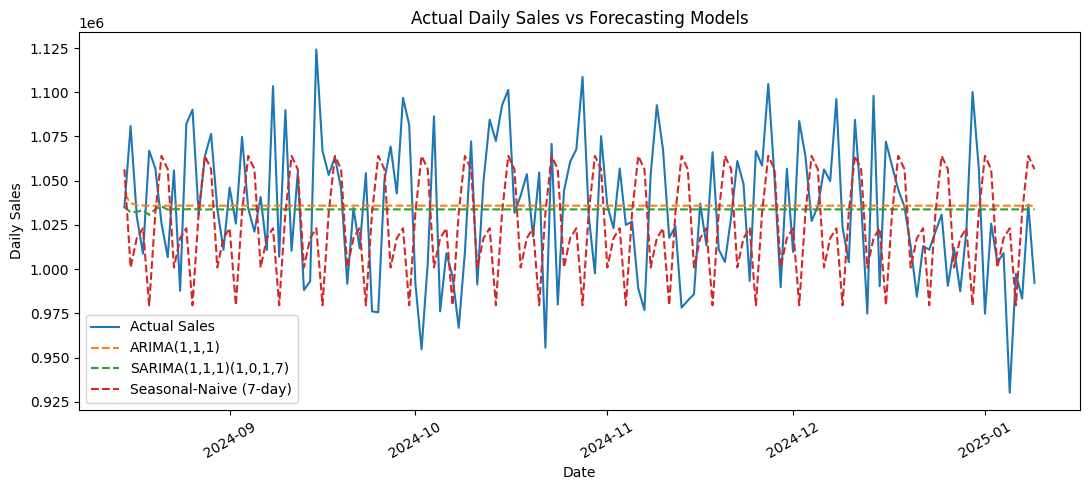


STEP 13 COMPLETED SUCCESSFULLY


In [0]:

# TASK 3C - STEP 13: SARIMA FORECASTING AND COMPARISON

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Reuse chronological data from Step 12
assert len(ts_train) == 592 and len(ts_test) == 148
assert arima_forecast.index.equals(ts_test.index)

# Train SARIMA
sarima_result = SARIMAX(
    ts_train,
    order=(1, 1, 1),
    seasonal_order=(1, 0, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False, maxiter=200)

converged = sarima_result.mle_retvals.get("converged", False)
print("SARIMA converged:", converged)
if not converged:
    raise RuntimeError("SARIMA did not converge. Review model settings.")

# Forecast 148 test days without using future actual sales
sarima_forecast = pd.Series(
    sarima_result.forecast(len(ts_test)).to_numpy(),
    index=ts_test.index
)

# Seasonal-naive baseline: repeat last 7 training days
seasonal_naive_forecast = pd.Series(
    np.resize(ts_train.iloc[-7:].to_numpy(), len(ts_test)),
    index=ts_test.index
)

# Calculate forecast errors
def evaluate(actual, predicted):
    a, p = actual.to_numpy(), predicted.to_numpy()
    return {
        "MAE": mean_absolute_error(a, p),
        "RMSE": np.sqrt(mean_squared_error(a, p)),
        "MAPE (%)": np.mean(
            np.abs((a[a != 0] - p[a != 0]) / a[a != 0])
        ) * 100 if np.any(a != 0) else np.nan
    }

models = {
    "ARIMA(1,1,1)": arima_forecast,
    "SARIMA(1,1,1)(1,0,1,7)": sarima_forecast,
    "Seasonal-Naive (7-day)": seasonal_naive_forecast
}

comparison_df = pd.DataFrame([
    {"Model": name, **evaluate(ts_test, pred)}
    for name, pred in models.items()
])

print("\n=== STEP 13: FORECAST COMPARISON ===")
display(comparison_df.round(4))

print("\n=== SAMPLE FORECASTS ===")
display(pd.DataFrame({
    "Date": ts_test.index,
    "Actual": ts_test.to_numpy(),
    "ARIMA": arima_forecast.to_numpy(),
    "SARIMA": sarima_forecast.to_numpy(),
    "SeasonalNaive": seasonal_naive_forecast.to_numpy()
}).head(10).round(2))

# Forecast comparison chart
plt.figure(figsize=(11, 5))
plt.plot(ts_test.index, ts_test, label="Actual Sales")
for name, pred in models.items():
    plt.plot(pred.index, pred, label=name, linestyle="--")
plt.title("Actual Daily Sales vs Forecasting Models")
plt.xlabel("Date")
plt.ylabel("Daily Sales")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print("\nSTEP 13 COMPLETED SUCCESSFULLY")


In [0]:

# TASK 3C - STEP 14: FINAL MODEL COMPARISON AND CONFIGURATION

import pandas as pd
import platform
import importlib.metadata

# 1. Databricks environment
print("=== DATABRICKS ENVIRONMENT ===")
print("Spark:", spark.version)
print("Python:", platform.python_version())
print("Compute: Databricks Serverless (verify in UI)")

for pkg in ["pyspark", "scikit-learn", "statsmodels"]:
    try:
        print(pkg, ":", importlib.metadata.version(pkg))
    except importlib.metadata.PackageNotFoundError:
        print(pkg, ": Not installed")

# 2. Classification comparison
# Values from verified Step 7 and Step 8 test outputs
print("\n=== CLASSIFICATION MODEL COMPARISON ===")

classification_results = pd.DataFrame([
    {"Model": "Majority-Class Baseline",
     "Accuracy": 0.3333, "Weighted F1": 0.1666},
    {"Model": "Random Forest Baseline",
     "Accuracy": 0.3339, "Weighted F1": 0.3337},
    {"Model": "Tuned Random Forest",
     "Accuracy": 0.3331, "Weighted F1": 0.3331}
])

display(classification_results.round(4))

# 3. Hyperparameter tuning
print("\n=== CLASSIFICATION HYPERPARAMETER TUNING ===")

tuning_results = pd.DataFrame([
    {"Trees": 20, "Max Depth": 5, "Validation F1": 0.3129},
    {"Trees": 50, "Max Depth": 8, "Validation F1": 0.3277},
    {"Trees": 80, "Max Depth": 10, "Validation F1": 0.3323}
])

display(tuning_results.round(4))

# 4. Regression comparison
print("\n=== REGRESSION MODEL COMPARISON ===")

regression_results = pd.DataFrame([
    {"Model": "Previous-Day Baseline",
     "MAE": 42147.9786, "RMSE": 51088.7274, "R2": -0.8059},
    {"Model": "Random Forest Regression",
     "MAE": 32026.1360, "RMSE": 39020.2878, "R2": -0.0535}
])

display(regression_results.round(4))

# 5. Forecast comparison from Step 13
print("\n=== TIME-SERIES FORECAST COMPARISON ===")

if "comparison_df" in globals():
    display(comparison_df.round(4))
else:
    print("Step 13 results unavailable. Rerun Step 13.")

# 6. Implementation challenges
print("\n=== IMPLEMENTATION CHALLENGES ===")

challenges = [
    "Explicit date parsing was required.",
    "Serverless required compatible Spark operations.",
    "statsmodels needed installation.",
    "Chronological splitting reduced temporal leakage.",
    "Classification accuracy remained near chance level.",
    "Tuning did not improve held-out classification accuracy.",
    "Forecast models struggled with daily sales fluctuations.",
    "One-step regression and 148-day forecasts are not directly comparable."
]

for i, challenge in enumerate(challenges, 1):
    print(f"{i}. {challenge}")

print("\nSTEP 14 COMPLETED SUCCESSFULLY")


=== DATABRICKS ENVIRONMENT ===
Spark: 4.2.0
Python: 3.12.3
Compute: Databricks Serverless (verify in UI)
pyspark : 4.3.0.dev0+databricks.connect.19.1
scikit-learn : 1.7.2
statsmodels : 0.15.0

=== CLASSIFICATION MODEL COMPARISON ===


Model,Accuracy,Weighted F1
Majority-Class Baseline,0.3333,0.1666
Random Forest Baseline,0.3339,0.3337
Tuned Random Forest,0.3331,0.3331



=== CLASSIFICATION HYPERPARAMETER TUNING ===


Trees,Max Depth,Validation F1
20,5,0.3129
50,8,0.3277
80,10,0.3323



=== REGRESSION MODEL COMPARISON ===


Model,MAE,RMSE,R2
Previous-Day Baseline,42147.9786,51088.7274,-0.8059
Random Forest Regression,32026.136,39020.2878,-0.0535



=== TIME-SERIES FORECAST COMPARISON ===


Model,MAE,RMSE,MAPE (%)
"ARIMA(1,1,1)",31713.8141,38069.0766,3.0811
"SARIMA(1,1,1)(1,0,1,7)",31638.0893,38046.0745,3.0674
Seasonal-Naive (7-day),41405.012,51029.4298,3.9909



=== IMPLEMENTATION CHALLENGES ===
1. Explicit date parsing was required.
2. Serverless required compatible Spark operations.
3. statsmodels needed installation.
4. Chronological splitting reduced temporal leakage.
5. Classification accuracy remained near chance level.
6. Tuning did not improve held-out classification accuracy.
7. Forecast models struggled with daily sales fluctuations.
8. One-step regression and 148-day forecasts are not directly comparable.

STEP 14 COMPLETED SUCCESSFULLY


In [0]:

# TASK 3C - STEP 15: FINAL DATASET AND MODEL VERIFICATION

import pandas as pd

print("=== TASK 3: FINAL VERIFICATION ===")
print("Spark Version:", spark.version)

# 1. Verify saved Delta tables
tables = {
    "Cleaned Sales": "workspace.default.dmart_sales_clean",
    "ML Features": "workspace.default.dmart_ml_features_3c",
    "Classification Train": "workspace.default.dmart_ml_train_3c",
    "Classification Test": "workspace.default.dmart_ml_test_3c",
    "Daily Sales": "workspace.default.dmart_daily_sales_3c",
    "Forecast Train": "workspace.default.dmart_forecast_train_3c",
    "Forecast Test": "workspace.default.dmart_forecast_test_3c"
}

records = []

for name, table in tables.items():
    try:
        df = spark.table(table)
        records.append({
            "Dataset": name,
            "Status": "AVAILABLE",
            "Records": df.count(),
            "Columns": len(df.columns)
        })
    except Exception:
        records.append({
            "Dataset": name,
            "Status": "NOT VERIFIED",
            "Records": None,
            "Columns": None
        })

print("\n=== SAVED DATASET VERIFICATION ===")
display(pd.DataFrame(records))

# 2. Verify model variables in current Python session
models = {
    "Baseline Classification": "rf_pipeline_model",
    "Tuned Classification": "best_rf_model",
    "Random Forest Regression": "regression_model",
    "ARIMA": "arima_result",
    "SARIMA": "sarima_result"
}

print("\n=== MODEL SESSION VERIFICATION ===")

model_status = pd.DataFrame([
    {
        "Model": name,
        "Session Status": (
            "AVAILABLE"
            if variable in globals()
            else "NOT IN SESSION"
        )
    }
    for name, variable in models.items()
])

display(model_status)

# 3. Verify forecast results
print("\n=== FORECASTING RESULTS ===")

if "comparison_df" in globals():
    display(comparison_df.round(4))
else:
    print("Forecast comparison not in session.")

# 4. Verify key outputs
print("\n=== FINAL OUTPUT VERIFICATION ===")

outputs = {
    "Classification Comparison": "classification_results",
    "Hyperparameter Tuning": "tuning_results",
    "Regression Comparison": "regression_results",
    "Forecast Comparison": "comparison_df"
}

for name, variable in outputs.items():
    print(
        name, ":",
        "AVAILABLE" if variable in globals()
        else "NOT IN SESSION"
    )

print("\nSTEP 15 VERIFICATION COMPLETED")


=== TASK 3: FINAL VERIFICATION ===
Spark Version: 4.2.0

=== SAVED DATASET VERIFICATION ===


Dataset,Status,Records,Columns
Cleaned Sales,AVAILABLE,1000000,14
ML Features,AVAILABLE,1000000,23
Classification Train,AVAILABLE,799908,23
Classification Test,AVAILABLE,200092,23
Daily Sales,AVAILABLE,740,4
Forecast Train,AVAILABLE,592,4
Forecast Test,AVAILABLE,148,4



=== MODEL SESSION VERIFICATION ===


Model,Session Status
Baseline Classification,NOT IN SESSION
Tuned Classification,NOT IN SESSION
Random Forest Regression,NOT IN SESSION
ARIMA,AVAILABLE
SARIMA,AVAILABLE



=== FORECASTING RESULTS ===


Model,MAE,RMSE,MAPE (%)
"ARIMA(1,1,1)",31713.8141,38069.0766,3.0811
"SARIMA(1,1,1)(1,0,1,7)",31638.0893,38046.0745,3.0674
Seasonal-Naive (7-day),41405.012,51029.4298,3.9909



=== FINAL OUTPUT VERIFICATION ===
Classification Comparison : AVAILABLE
Hyperparameter Tuning : AVAILABLE
Regression Comparison : AVAILABLE
Forecast Comparison : AVAILABLE

STEP 15 VERIFICATION COMPLETED


In [0]:
print("=== SAVED MODEL CHECK ===")

display(
    spark.sql("SHOW TABLES IN workspace.default")
    .filter("tableName LIKE '%model%'")
)

=== SAVED MODEL CHECK ===


database,tableName,isTemporary
default,dmart_rf_model_comparison_3c,false


In [0]:
display(
    spark.sql("""
        SHOW TABLES IN workspace.default
        LIKE 'dmart_rf*'
    """)
)

database,tableName,isTemporary
default,dmart_rf_classification_report_3c,false
default,dmart_rf_model_comparison_3c,false
default,dmart_rf_tuning_results_3c,false


In [0]:
# STEP 15 - ADDITIONAL SAVED RESULTS VERIFICATION

tables = [
    "dmart_rf_classification_report_3c",
    "dmart_rf_model_comparison_3c",
    "dmart_rf_tuning_results_3c"
]

print("=== PERSISTED MACHINE LEARNING RESULTS ===")

for name in tables:
    table = f"workspace.default.{name}"
    df = spark.table(table)
    print(f"{name}: VERIFIED ({df.count()} rows)")

print("\nSaved results remain available after session restart.")

=== PERSISTED MACHINE LEARNING RESULTS ===
dmart_rf_classification_report_3c: VERIFIED (3 rows)
dmart_rf_model_comparison_3c: VERIFIED (3 rows)
dmart_rf_tuning_results_3c: VERIFIED (3 rows)

Saved results remain available after session restart.


In [0]:

# TASK 3B - STEP 16: MACHINE LEARNING LIFECYCLE

import pandas as pd

stages = [
    ("1. Data Ingestion", "DMart sales CSV", "Step 1"),
    ("2. Data Storage", "Cleaned Delta Lake table", "Steps 2-3"),
    ("3. Feature Engineering", "23 ML feature columns", "Steps 3-4"),
    ("4. Data Splitting", "Chronological train/test split", "Steps 5-6"),
    ("5. Classification", "Random Forest classifier", "Step 7"),
    ("6. Hyperparameter Tuning", "RF parameter comparison", "Step 8"),
    ("7. Regression", "Random Forest sales prediction", "Steps 9-10"),
    ("8. Time-Series Forecasting", "ARIMA, SARIMA and baseline", "Steps 11-13"),
    ("9. Model Evaluation", "Accuracy, F1, MAE, RMSE, MAPE", "Steps 7-14"),
    ("10. Result Verification", "Saved Delta tables and evaluation results", "Step 15")
]

lifecycle_df = pd.DataFrame(
    stages,
    columns=["Lifecycle Stage", "Implementation", "Evidence"]
)

print("=== DATABRICKS MACHINE LEARNING LIFECYCLE ===")
display(lifecycle_df)

print("\n=== SAVED DATA VERIFICATION ===")
for table in [
    "dmart_sales_clean",
    "dmart_ml_features_3c",
    "dmart_daily_sales_3c",
    "dmart_rf_model_comparison_3c"
]:
    full_name = f"workspace.default.{table}"
    print(table, ":", "AVAILABLE"
          if spark.catalog.tableExists(full_name)
          else "NOT FOUND")

print("\nSTEP 16 COMPLETED")


=== DATABRICKS MACHINE LEARNING LIFECYCLE ===


Lifecycle Stage,Implementation,Evidence
1. Data Ingestion,DMart sales CSV,Step 1
2. Data Storage,Cleaned Delta Lake table,Steps 2-3
3. Feature Engineering,23 ML feature columns,Steps 3-4
4. Data Splitting,Chronological train/test split,Steps 5-6
5. Classification,Random Forest classifier,Step 7
6. Hyperparameter Tuning,RF parameter comparison,Step 8
7. Regression,Random Forest sales prediction,Steps 9-10
8. Time-Series Forecasting,"ARIMA, SARIMA and baseline",Steps 11-13
9. Model Evaluation,"Accuracy, F1, MAE, RMSE, MAPE",Steps 7-14
10. Result Verification,Saved Delta tables and evaluation results,Step 15



=== SAVED DATA VERIFICATION ===
dmart_sales_clean : AVAILABLE
dmart_ml_features_3c : AVAILABLE
dmart_daily_sales_3c : AVAILABLE
dmart_rf_model_comparison_3c : AVAILABLE

STEP 16 COMPLETED


In [0]:

# TASK 3B - STEP 17: SERVERLESS COMPUTE AND EXECUTION

import platform
from pyspark.sql import functions as F

print("=== COMPUTE CONFIGURATION ===")
print("Spark Version:", spark.version)
print("Python Version:", platform.python_version())
print("Compute: Databricks Serverless (verify in UI)")

print("\n=== SPARK EXECUTION SETTINGS ===")
for key in ["spark.sql.shuffle.partitions",
            "spark.sql.adaptive.enabled"]:
    try:
        print(key, ":", spark.conf.get(key))
    except Exception:
        print(key, ": Managed or unavailable")

# Load saved Delta dataset
df = spark.table("workspace.default.dmart_sales_clean")

print("\n=== DATASET VERIFICATION ===")
print("Total Records:", df.count())
print("Total Columns:", len(df.columns))

# Serverless-compatible partition demonstration
partitioned_df = df.repartition(4)

partition_results = (
    partitioned_df
    .withColumn("PartitionID", F.spark_partition_id())
    .groupBy("PartitionID")
    .count()
    .orderBy("PartitionID")
)

print("\n=== DISTRIBUTED PARTITION VERIFICATION ===")
display(partition_results)

print("\nSTEP 17 COMPLETED SUCCESSFULLY")


=== COMPUTE CONFIGURATION ===
Spark Version: 4.2.0
Python Version: 3.12.3
Compute: Databricks Serverless (verify in UI)

=== SPARK EXECUTION SETTINGS ===
spark.sql.shuffle.partitions : auto
spark.sql.adaptive.enabled : Managed or unavailable

=== DATASET VERIFICATION ===
Total Records: 1000000
Total Columns: 14

=== DISTRIBUTED PARTITION VERIFICATION ===


PartitionID,count
0,250000
1,250000
2,250000
3,250000



STEP 17 COMPLETED SUCCESSFULLY
